/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   

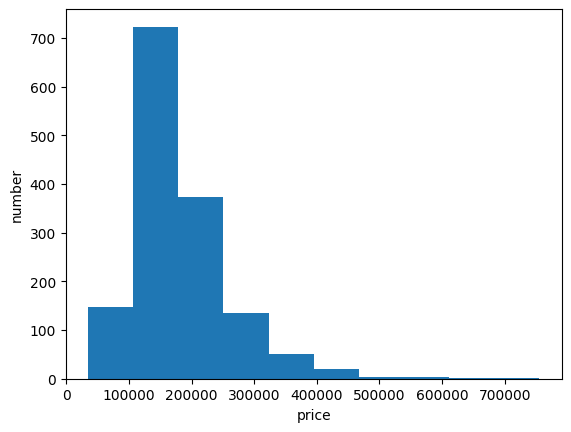

1.8828757597682129
対数変化後の値: 0       12.247694
1       12.109011
2       12.317167
3       11.849398
4       12.429216
          ...    
1455    12.072541
1456    12.254863
1457    12.493130
1458    11.864462
1459    11.901583
Name: SalePrice, Length: 1460, dtype: float64
0.12133506220520406


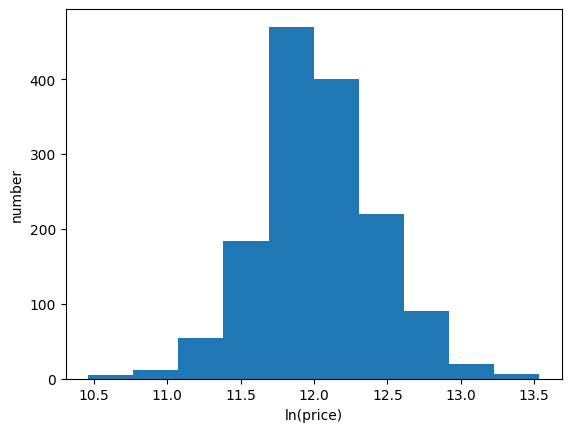

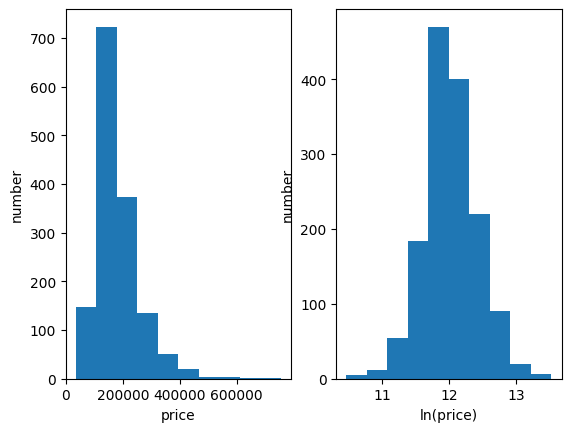

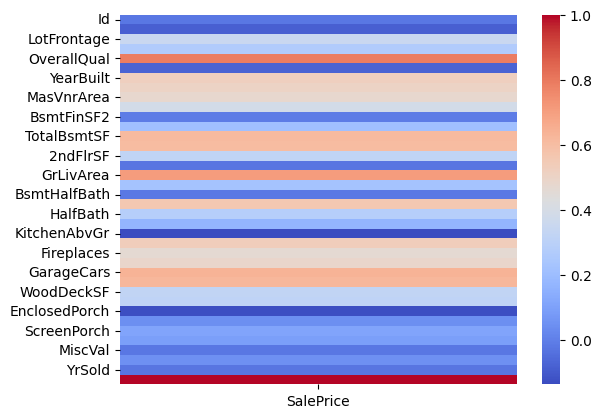

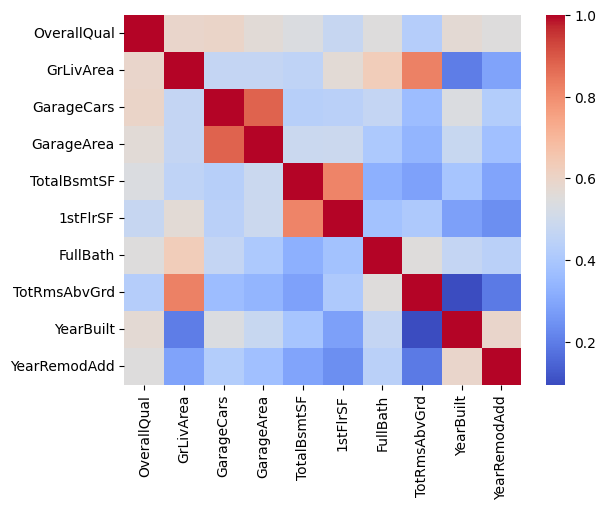

件数: PoolQC
NaN    1453
Gd        3
Ex        2
Fa        2
Name: count, dtype: int64


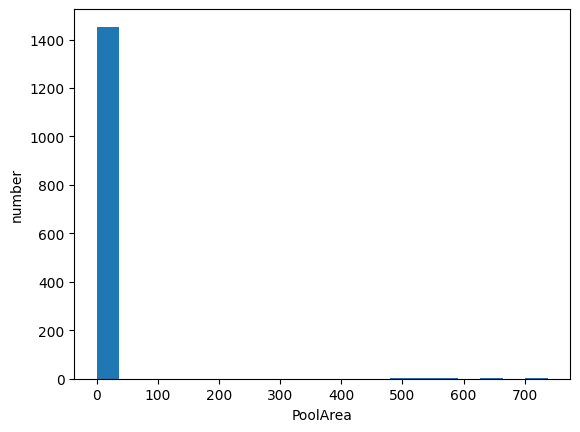

プール無しの件数: 1453
プール有りの件数: 7
        Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0        1          60       RL         65.0     8450   Pave   NaN      Reg   
1        2          20       RL         80.0     9600   Pave   NaN      Reg   
2        3          60       RL         68.0    11250   Pave   NaN      IR1   
3        4          70       RL         60.0     9550   Pave   NaN      IR1   
4        5          60       RL         84.0    14260   Pave   NaN      IR1   
...    ...         ...      ...          ...      ...    ...   ...      ...   
1455  1456          60       RL         62.0     7917   Pave   NaN      Reg   
1456  1457          20       RL         85.0    13175   Pave   NaN      Reg   
1457  1458          70       RL         66.0     9042   Pave   NaN      Reg   
1458  1459          20       RL         68.0     9717   Pave   NaN      Reg   
1459  1460          20       RL         75.0     9937   Pave   NaN      Reg   

     LandContour Utiliti

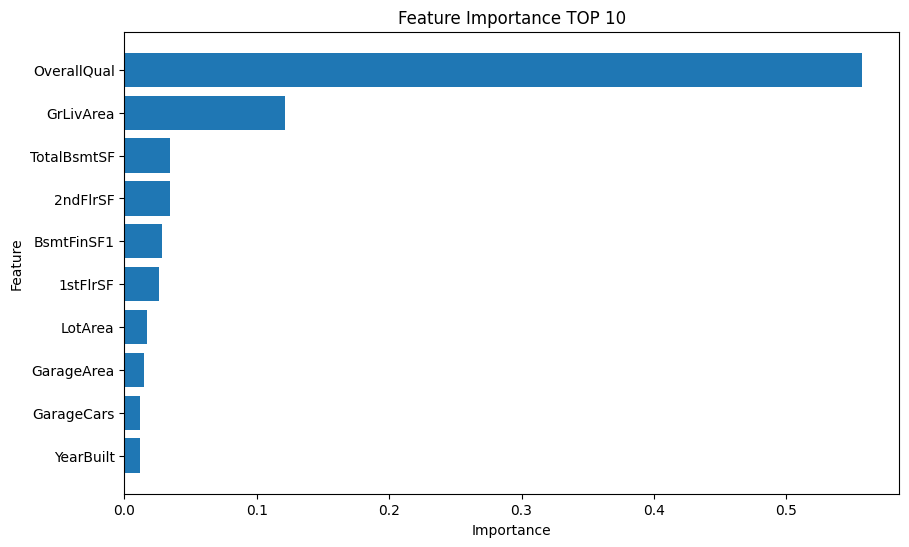

Train R2: 0.9789028566536458
Validation R2: 0.8912140220941969


In [10]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib as plt

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
file = pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv")
print(file.head(5))
print(file.shape)
print("type:", file.dtypes)
print("missing value:", file.isnull().sum())
print(file.loc[:, file.isnull().sum() > 1])
ratio = (file.isnull().sum() / len(file)) * 100
print("欠損割合:", ratio)
print(ratio.loc[ratio > 50])
ratio.sort_values(ascending=False)
print(file["SalePrice"].describe())

#ヒストグラムの作成
import matplotlib.pyplot as plt

data = file["SalePrice"]
plt.hist(data)
plt.xlabel("price")
plt.ylabel("number")
plt.show()

print(file["SalePrice"].skew())
Logarithm=np.log(file["SalePrice"])
print("対数変化後の値:",Logarithm)
print(Logarithm.skew())

#ヒストグラムの比較
plt.hist(Logarithm)
plt.xlabel("ln(price)")
plt.ylabel("number")
plt.show()

plt.subplot(1,2,1)
plt.hist(data)
plt.xlabel("price")
plt.ylabel("number")

plt.subplot(1,2,2)
plt.hist(Logarithm)
plt.xlabel("ln(price)")
plt.ylabel("number")
plt.show()

#相関係数の比較
corr=file.corr(numeric_only=True)
corr["SalePrice"].sort_values(ascending=False).head(10)

#ヒートマップの作成
import seaborn as sns
sns.heatmap(
  data=corr[["SalePrice"]],
  annot=False,
  cmap="coolwarm"
  )
plt.show()

a=corr.loc[corr["SalePrice"]<1]
top_10th_data=a["SalePrice"].nlargest(10)
new_data=corr.loc[top_10th_data.index, top_10th_data.index]

#ヒートマップの作成
sns.heatmap(
  data=new_data,
  annot=False,
  cmap="coolwarm"
  )
plt.show()

#プールのデータ処理してヒストグラムの作成
miss_data = file.isnull().sum()
miss_data.sort_values(ascending=False)
miss_ratio=(file.isnull().sum()/len(file))*100
miss_ratio[miss_ratio > 50].sort_values(ascending=False)
print("件数:",file["PoolQC"].value_counts(dropna=False))

file[["PoolArea","SalePrice"]].corr()

plt.hist(file["PoolArea"],bins=20)
plt.xlabel("PoolArea")
plt.ylabel("number")
plt.show()

print("プール無しの件数:",file[file["PoolArea"]==0].shape[0])
print("プール有りの件数:",file[file["PoolArea"]>0].shape[0])

file["PoolQC"] = file["PoolQC"].fillna("None")
print(file)

#MiscFeatureの欠損データの処理
miss_ration_MiscFeature=(file["MiscFeature"].isnull().sum() / len(file)) * 100
print(miss_ration_MiscFeature)
print(file["MiscFeature"].value_counts())
file["MiscFeature"]=file["MiscFeature"].fillna("None")
print(file)

#Alleyの欠損データの処理
miss_ration_Alley=(file["Alley"].isnull().sum()/len(file))*100
print(miss_ration_Alley)
print(file["Alley"].value_counts())
file["Alley"]=file["Alley"].fillna("None")

#Fenceの欠損データの処理
miss_ration_Fence=(file["Fence"].isnull().sum()/len(file))*100
print(miss_ration_Fence)
print(file["Fence"].value_counts())
file["Fence"]=file["Fence"].fillna("None")

#MasVnrTypeの欠損データの処理
miss_ration_MasVnrType=(file["MasVnrType"].isnull().sum()/len(file))*100
print(miss_ration_MasVnrType)
print(file["MasVnrType"].value_counts())
file["MasVnrType"]=file["MasVnrType"].fillna("None")

file.isnull().sum().sort_values(ascending=False)

#Fireplacesの欠損データの処理
miss_ration_Fireplaces=(file["Fireplaces"].isnull().sum()/len(file))*100
print(miss_ration_Fireplaces)
print(file["Fireplaces"].value_counts())
file[(file["Fireplaces"]==0)&(file["FireplaceQu"].isnull()==1)]
file["Fireplaces"]=file["Fireplaces"].fillna("None")

#GarageQualの欠損データの処理
miss_ration_GarageQual=(file["GarageQual"].isnull().sum()/len(file))*100
print(miss_ration_GarageQual)
print(file["GarageQual"].value_counts())
file[(file["GarageType"]==0)&(file["GarageQual"].isnull()==1)]
file["GarageQual"]=file["GarageQual"].fillna("None")

Missing_row=file[file["GarageQual"].isnull()==1]
print(Missing_row["GarageType"].value_counts())

print("GarageQual:",file["GarageQual"].isnull().sum())
print("GarageType:",file["GarageType"].isnull().sum())

#GarageTypの欠損データの処理
miss_ration_GarageType=(file["GarageType"].isnull().sum()/len(file))*100
print(miss_ration_GarageType)
print(file["GarageType"].value_counts())
file["GarageCars"].loc[file["GarageType"].isnull()==1].value_counts()
file["GarageCars"]=file["GarageCars"].fillna("None")

file["GarageCars"].loc[file["GarageYrBlt"].isnull()].value_counts()
file["GarageYrBlt"]=file["GarageYrBlt"].fillna(0)

file["GarageCars"].loc[file["GarageCond"].isnull()].value_counts()
file["GarageCond"]=file["GarageCond"].fillna("None")

print(file.isnull().sum())

file.loc[:,file.isnull().sum()>=1]
file.isnull().sum().sort_values(ascending=False)
file["GarageType"]=file["GarageType"].fillna("None")

file["FireplaceQu"].isnull().sum()
file["GarageType"].isnull().sum()

file.loc[file["GarageFinish"].isnull(), ["GarageCars", "GarageType"]]

file["GarageFinish"]=file["GarageFinish"].fillna("None")

file.isnull().sum()[file.isnull().sum()>0].sort_values(ascending=False)

#FireplaceQuの欠損データの置き換え
file["FireplaceQu"]=file["FireplaceQu"].fillna("None")

# LotFrontageの欠損値がある行の確認
file["LotFrontage"].isnull().sum()

#LotFrontage のデータ処理
missing_area=file.loc[file["LotFrontage"].isnull(),"Neighborhood"]
missing_area.value_counts()
file.groupby("Neighborhood")["LotFrontage"].median()

file["LotFrontage"].isnull().sum()
file["LotFrontage"].median()
lot_median=file.groupby("Neighborhood")["LotFrontage"].transform("median")

lot_median.isnull().sum()
file["LotFrontage"]=file["LotFrontage"].fillna(lot_median)
file["LotFrontage"].isnull().sum()


#それぞれのBsmでデータ欠損してる時の地下室面積を確認
file.loc[file["BsmtQual"].isnull(),"TotalBsmtSF"]
file.loc[file["BsmtExposure"].isnull(),"TotalBsmtSF"]
file.loc[file["BsmtFinType1"].isnull(),"TotalBsmtSF"]
file.loc[file["BsmtFinType2"].isnull(),"TotalBsmtSF"]
file.loc[file["BsmtCond"].isnull(),"TotalBsmtSF"]

#それぞれのBsmの欠損値を置き換え
file["BsmtQual"]=file["BsmtQual"].fillna("None")
file["BsmtExposure"]=file["BsmtExposure"].fillna("None")
file["BsmtFinType1"]=file["BsmtFinType1"].fillna("None")
file["BsmtFinType2"]=file["BsmtFinType2"].fillna("None")
file["BsmtCond"]=file["BsmtCond"].fillna("None")

#欠損している住宅のMasVnrTypeを確認し、データの置き換え
file.loc[file["MasVnrArea"].isnull(),"MasVnrType"]
file["MasVnrArea"]=file["MasVnrArea"].fillna(0)

#Electricalが欠損している住宅の情報を確認し、データの置き換え
file.loc[file["Electrical"].isnull(),"MasVnrType"]
file["Electrical"].value_counts()
file["Electrical"]=file["Electrical"].fillna(file["Electrical"].mode()[0])

# 欠損値が残っている列を確認する
file.isnull().sum()[file.isnull().sum() > 0].sort_values(ascending=False)

#欠損値を処理できていなかったため、もう一回LotFrontage のデータ処理
file["LotFrontage"].isnull().sum()
lot_median=file.groupby("Neighborhood")["LotFrontage"].transform("median")
file["LotFrontage"]=file["LotFrontage"].fillna(lot_median)
print(lot_median.isnull().sum())
print(file["LotFrontage"].isnull().sum())

missing_data = file.isnull().sum()
missing_data[missing_data > 0].sort_values(ascending=False)

#機械学習のデータの設定
x=file.drop("SalePrice", axis=1)
y=file["SalePrice"]

#訓練データとテストデータを分割
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

#訓練データとテストデータの列を合わせる
x_train = pd.get_dummies(x_train)
x_test = pd.get_dummies(x_test)
x_train, x_test = x_train.align(
    x_test,
    join="left",
    axis=1,
    fill_value=0
)

#モデルの検証
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
models=[LinearRegression(),
        DecisionTreeRegressor(max_depth=None,random_state=42),
        RandomForestRegressor(n_estimators=100,max_depth=None,random_state=42)
       ]
for model in models:
    score=cross_val_score(
    model,x_train,y_train,cv=5,scoring="r2"
        )
    print(type(model).__name__)
    print(score)
    print(score.mean())

model.fit(x_train,y_train)
y_pred=model.predict(x_test)

#ランダムフォレストのパラメータの決定
from sklearn.model_selection import GridSearchCV
model=RandomForestRegressor(random_state=42)

param_grid={
    "n_estimators":[1,10,50,100],
    "max_depth":[1,5,10,100,None]
}

grid=GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1
)
grid.fit(x_train,y_train)
print("最も良い組み合わせ:",grid.best_params_)
print("最も良いモデル:",grid.best_estimator_)

#予測精度の確認
from sklearn.metrics import mean_absolute_error,r2_score
best_model=grid.best_estimator_
y_pred=best_model.predict(x_test)

print("最終MAE:", mean_absolute_error(y_test, y_pred))
print("最終R2:", r2_score(y_test, y_pred))

print(best_model)
print(x_train.shape)
print(file.shape)

#テストデータの確認
test=pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv")
test.head()
test.isnull().sum().sort_values(ascending=False)

#テストデータの欠損値の処理(訓練データと同様の処理) 
#Noneで置き換える
test["PoolQC"]=test["PoolQC"].fillna("None")
test["MiscFeature"]=test["MiscFeature"].fillna("None")
test["Alley"]=test["Alley"].fillna("None")
test["Fence"]=test["Fence"].fillna("None")
test["MasVnrType"]=test["MasVnrType"].fillna("None")
test["GarageQual"]=test["GarageQual"].fillna("None")
test["GarageCond"]=test["GarageCond"].fillna("None")
test["GarageType"]=test["GarageType"].fillna("None")
test["GarageFinish"]=test["GarageFinish"].fillna("None")
test["FireplaceQu"]=test["FireplaceQu"].fillna("None")
test["BsmtQual"]=test["BsmtQual"].fillna("None")
test["BsmtExposure"]=test["BsmtExposure"].fillna("None")
test["BsmtFinType1"]=test["BsmtFinType1"].fillna("None")
test["BsmtFinType2"]=test["BsmtFinType2"].fillna("None")
test["BsmtCond"]=test["BsmtCond"].fillna("None")

#中央値で置き換える
lot_median=file.groupby("Neighborhood")["LotFrontage"].median()
test_lot_median=test["Neighborhood"].map(lot_median)
test["LotFrontage"]=test["LotFrontage"].fillna(test_lot_median)

test["BsmtFullBath"]=test["BsmtFullBath"].fillna(file["BsmtFullBath"].median())
test["BsmtHalfBath"]=test["BsmtHalfBath"].fillna(file["BsmtHalfBath"].median())
test["TotalBsmtSF"]=test["TotalBsmtSF"].fillna(file["TotalBsmtSF"].median())
test["BsmtUnfSF"]=test["BsmtUnfSF"].fillna(file["BsmtUnfSF"].median())
test["BsmtFinSF1"]=test["BsmtFinSF1"].fillna(file["BsmtFinSF1"].median())
test["BsmtFinSF2"]=test["BsmtFinSF2"].fillna(file["BsmtFinSF2"].median())
test["GarageCars"]=test["GarageCars"].fillna(file["GarageCars"].median())
test["GarageArea"]=test["GarageArea"].fillna(file["GarageArea"].median())

#0で置き換える
test["MasVnrArea"]=test["MasVnrArea"].fillna(0)
test["GarageYrBlt"]=test["GarageYrBlt"].fillna(0)

#最頻値で置き換える
test["Electrical"]=test["Electrical"].fillna(file["Electrical"].mode()[0])
test["MSZoning"]=test["MSZoning"].fillna(file["MSZoning"].mode()[0])
test["Utilities"]=test["Utilities"].fillna(file["Utilities"].mode()[0])
test["Functional"]=test["Functional"].fillna(file["Functional"].mode()[0])
test["Exterior1st"]=test["Exterior1st"].fillna(file["Exterior1st"].mode()[0])
test["Exterior2nd"] = test["Exterior2nd"].fillna(file["Exterior2nd"].mode()[0])
test["KitchenQual"]=test["KitchenQual"].fillna(file["KitchenQual"].mode()[0])
test["Functional"]=test["Functional"].fillna(file["Functional"].mode()[0])
test["SaleType"]=test["SaleType"].fillna(file["SaleType"].mode()[0])

test.isnull().sum()[test.isnull().sum() > 0]

#x_testの列と行を整える
test_binary=pd.get_dummies(test)
test_binary=test_binary.reindex(columns=x_train.columns, fill_value=0)

print(x_train.shape)
print(test_binary.shape)

#テストデータでの予測
test_pred=best_model.predict(test_binary)
print(len(test_pred))
print(test_pred[:5])

#提出物
submission=pd.DataFrame(
    {'Id':test["Id"],
    'SalePrice':test_pred}
)

print(submission.head())
print(submission.shape)

submission.to_csv("submission.csv", index=False)

#特徴量重要度の確認
importance=best_model.feature_importances_
importance.tolist()
importance_df = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance": importance
})
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)
print(importance_df.head(10))

#グラフ化
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"].head(10),
    importance_df["Importance"].head(10)
)

plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance TOP 10")
plt.show()

print("Train R2:", best_model.score(x_train, y_train))
print("Validation R2:", best_model.score(x_test, y_test))